# 14c — Estimate growth parameters, then test a withheld forecast

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/14c_growth_parameter_recovery.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

Running an equation forward with assigned rates is different from learning those rates from observations. We can study the inverse problem without confusing a fit with a clinical prediction: generate observations on known BrainWeb anatomy, hide the generating rates from a grid search, then evaluate a later time that did not enter fitting.

The source anatomy is the normal phantom; all tumour observations and their noise are generated here. This controlled experiment lets us compare estimates with known values and identify the assumptions that made recovery possible.

### Learning goals

1. Distinguish a forward simulation, an observation model, parameter fitting and a withheld forecast.
2. Fit two parameters to generated spatial observations while keeping later data out of selection.
3. Compare a mechanistic forecast with a simple persistence baseline.
4. Explain why a bounded search and a successful synthetic forecast do not provide clinical confidence intervals or patient validation.

## Concepts and two reading paths

<details open><summary><strong>For biomedical and imaging readers</strong></summary>

A **forward problem** asks what the model produces for chosen rates. An **inverse problem** asks which rates could explain observed changes. An **observation model** describes how an unobserved density becomes a recorded quantity; here it is only a local average plus generated noise, not a model of MRI contrast.

**Withholding** means protecting a later observation from parameter selection. **Persistence** predicts that the last observed spatial map remains unchanged. Comparing against it tests whether modelling adds value for this generated problem.

**Identifiability** asks whether the observations distinguish parameter choices. An exact-looking estimate on a coarse search grid is not a precise biological estimate. Unknown seed, tissue mapping, carrying capacity and measurement calibration would add further ambiguity in practice.

</details>

<details><summary><strong>For computational readers</strong></summary>

The unknowns are a multiplier $s$ of both assigned tissue diffusivities and a shared proliferation rate $\rho$. The WM:GM ratio stays fixed at five; this is a strong assumption, not an estimated result. The seed and tissue geometry are known.

For each candidate pair, the solver predicts block-averaged density at days 20, 40 and 60. Mean squared residuals are calculated within a prespecified physical cube. Day 90 is withheld. The generator uses 0.5-day steps and candidates use 1-day steps, but they share the equation, spatial grid and observation operator. This is deliberately favourable synthetic recovery, not a test against an independent biological process.

The search is frequentist least squares on a bounded grid. No Bayesian prior, bootstrap, interval coverage study or calibrated uncertainty interval is implemented.

</details>

### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime and run all cells in order. Setup obtains the shared code and dependencies. Locally, use the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks), select the project kernel and restart and run all cells. No earlier notebook needs to have run.

Save a notebook copy in Drive to retain edits. Download generated figures or JSON records before a Colab runtime ends. Results are written under the ignored `.build/` directory, separately from the saved notebook.

The two checksum-pinned normal BrainWeb files (about 9.25 MB) are [bundled here](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/brainweb/README.md). After checkout and dependency setup, the calculations need no network or companion repository.

In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8", "ipywidgets>=8.1", "nibabel>=5.3,<6"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.
if IN_COLAB:
    from google.colab import output
    output.enable_custom_widget_manager()

from brainsmodels import growth_lessons as lessons
OUTPUT = root / '.build/growth-14c'
OUTPUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})

def show_figure(fig, name):
    fig.savefig(OUTPUT / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Python: 3.12.2 | NumPy: 2.5.2


## 1. Generate the experiment before fitting

The state is $u=c/K$, cell density $c$ divided by an assumed constant carrying capacity $K$. It is a dimensionless fraction, not a probability. The forward equation is

$$\frac{\partial u}{\partial t}=\nabla\cdot(D(\mathbf{x})\nabla u)+\rho u(1-u).$$

Read this as change in density = spatial redistribution + local growth. The gradient $\nabla u$ describes spatial differences; the divergence $\nabla\cdot$ gives the net redistribution into each voxel. $D$ is scalar diffusivity in mm²/day; $\rho$ is a proliferation rate in day⁻¹. The growth domain includes grey matter, white matter and glial class 8; the last shares the grey-matter rate. Other classes, including CSF, are excluded with no transfer through their faces. These are modelling assumptions.

The initial state is a Gaussian density seed with standard deviation 8 mm and peak $u=0.12$, centred at (−24, −12, 24) mm in RAS+ coordinates (axes increasing rightward, anteriorly and superiorly) and masked to the growth domain. All candidates share this known initial state.

The known generator uses $D_{WM}=0.5$, $D_{GM}=0.1$ mm²/day and $\rho=0.04$ day⁻¹, so the true multiplier is $s=1$. A 6 mm grid keeps the repeated simulations small. Its anatomy is sampled explicitly; it is coarser than 14b and is not a spatially converged representation.

At each observation time, average each non-overlapping $2\times2\times2$ block. Thus the observed grid has 12 mm blocks. Trim unmatched high-index edge cells consistently. Define a 72 mm cube around the known seed before generating noise or fitting. The T1 intensity is never used in this observation operator.

$$y_i=\mathcal{B}[u(t_i;s,\rho)]+\epsilon_i,\qquad \epsilon_i\sim\mathcal{N}(0,0.005^2).$$

$\mathcal{B}$ denotes the block-mean operation; $y_i$ is a generated density proxy. Independent Gaussian noise is added to each block and time, using seed 7. It is not clipped, so some noisy values can fall outside [0,1]. Those are observations of a bounded state with additive noise, not negative cell densities.

In [2]:
from brainsmodels.brainweb_data import load_brainweb, COMMIT
brain = load_brainweb(step_mm=6)
problem = lessons.recovery_problem(brain)
print('Data source:', COMMIT)
print('Generator grid:', brain.labels.shape, '| spacing:', brain.spacing_mm, 'mm')
print('Fit days:', problem['fit_days'][1:], '| withheld: day 90')
print('Observation cube blocks:', problem['roi'].sum(), '| noise SD:', problem['noise_sd'])
print('Candidate D multipliers:', problem['scales'])
print('Candidate rho values:', problem['rhos'], '/day')

Data source: 81ecd42e6f37692a711208caa8d24361904f7e65
Generator grid: (31, 37, 31) | spacing: (6, 6, 6) mm
Fit days: [20. 40. 60.] | withheld: day 90
Observation cube blocks: 216 | noise SD: 0.005
Candidate D multipliers: [0.6 0.7 0.8 0.9 1.  1.1 1.2 1.3 1.4]
Candidate rho values: [0.025 0.03  0.035 0.04  0.045 0.05  0.055] /day


## 2. Fit only the early observations

The loss averages squared differences between predicted and observed density proxies within the fixed cube. All spatial blocks receive equal weight. The fitting function receives only days 0, 20, 40, 60 and observations from the three nonzero times. It does not receive the day-90 observation.

**Predict:** would an observation at day zero identify either growth or dispersal? What would an estimate at the edge of the candidate grid tell you to investigate?

In [3]:
fit = lessons.fit_recovery_problem(problem)
print('Estimated D multiplier:', fit['scale'], '| known:', 1.)
print('Estimated rho:', fit['rho'], '/day | known:', .04, '/day')
print('Best estimate touches search boundary:', fit['at_boundary'])
print('Smallest fit RMSE:', np.sqrt(fit['losses'].min()))
# At t=0 every candidate shares the same specified initial condition.
print('Time-zero predictions do not depend on D or rho: they share the initial state.')

Estimated D multiplier: 1.0 | known: 1.0
Estimated rho: 0.04 /day | known: 0.04 /day
Best estimate touches search boundary: False
Smallest fit RMSE: 0.004973572088145487
Time-zero predictions do not depend on D or rho: they share the initial state.


### Interpret the estimate before forecasting

The selected pair is the best of 63 candidates, not the solution of a continuous optimization problem. In this particular realization it can coincide with the known pair because that pair is included in the grid. Do not infer precision from the number of printed digits.

Neighbouring candidates in the cost surface show which changes the observations distinguish at this resolution. A flat valley would signal a trade-off; a minimum on the search boundary would call for checking the ranges and model. Candidate ranges constrain the search but are not a confidence interval.

Time-zero observations cannot reveal rates: all candidates start from the same given seed. The numerical checks separately test parameter selection against known generated targets.

## 3. Freeze the parameters and reveal day 90

Now propagate the selected model to day 90. Compare its predicted block means with the withheld noisy observation, using the same prespecified cube and RMSE. A persistence baseline copies the observed day-60 block means forward without growth.

The plot averages across the cube for readability; fitting and reported RMSE use the spatial blocks individually. A matching mean alone would not demonstrate spatial agreement.

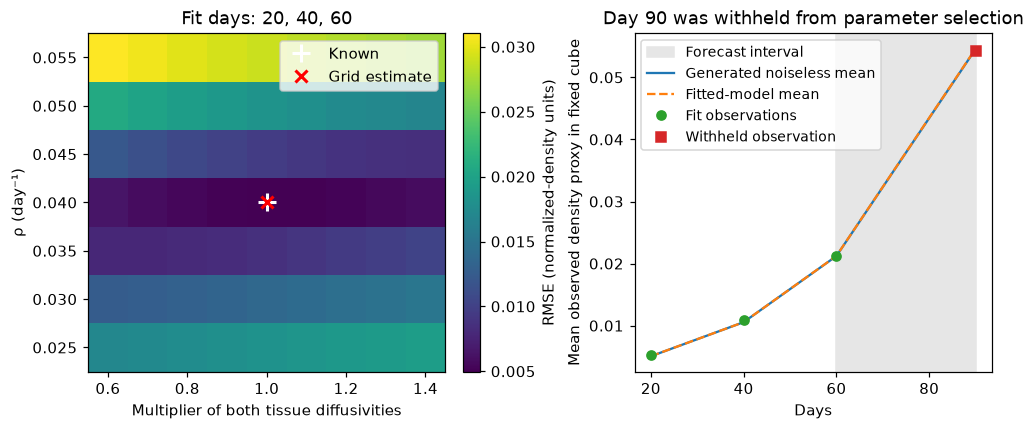

{
  "known_scale": 1.0,
  "known_rho_per_day": 0.04,
  "estimated_scale": 1.0,
  "estimated_rho_per_day": 0.04,
  "search_boundary": false,
  "noise_sd": 0.005,
  "seed": 7,
  "fit_days": [
    20.0,
    40.0,
    60.0
  ],
  "withheld_day": 90.0,
  "fit_rmse": 0.004973572088145487,
  "withheld_rmse": 0.004650847122130164,
  "persistence_withheld_rmse": 0.06287739346941636,
  "withheld_clean_rmse": 0.0001213643725373056,
  "observation_voxels_in_roi": 216,
  "generator_dt_days": 0.5,
  "fit_dt_days": 1.0,
  "shared_spatial_grid_and_model": true
}


553

In [4]:
result = lessons.recovery_forecast(problem, fit)
show_figure(lessons.plot_recovery(result), 'fit-and-withheld-forecast')
print(json.dumps(result['summary'], indent=2))
(OUTPUT / 'recovery.json').write_text(json.dumps(result['summary'], indent=2)+'\n')

### What the comparison means

For this seed and observation design, compare the fitted forecast's withheld RMSE with persistence. Also inspect the error against the generated noiseless field: this separates remaining state-prediction discrepancy from added measurement noise in this controlled example.

A successful forecast is conditional on unusually favourable knowledge: the correct model family, seed, geometry, tissue ratio, carrying capacity normalization and observation operator. The generator also shares the spatial grid with the fitting solver. Different time steps reduce one numerical identity but do not remove these shared assumptions. Repeated noise realizations, alternate observation models and independent spatial discretizations would be needed for broader recovery claims.

No bootstrap or parameter confidence interval is reported. A single noise realization cannot establish interval coverage or general robustness.

## Interactive experiment: what makes recovery easier or harder?

Choose generating rates, noise level and seed; choose early observation times, candidate-grid resolution and fitting time step. Press **Fit and forecast** to run the complete controlled experiment. The anatomy stays at 6 mm. The generator always uses 0.5-day steps; the fitting-step control changes candidates and the selected forecast.

Day 90 remains withheld for every setting. Persistence uses the latest **selected** training observation, so selecting day 20 alone gives a day-20 persistence baseline. Fitting still estimates one common multiplier of both tissue diffusivities; their ratio remains fixed. The displayed known point changes with the generating controls. A fine candidate grid does not provide a confidence interval.

**Try:** compare one and three training times using the same noise seed, then repeat several prespecified seeds at higher noise. Can you distinguish a broad cost-surface valley from a minimum shifted by noise or coarse candidate spacing?

The button runs on CPU without external simulations or data downloads. GitHub shows static reference results; controls need a live Colab, JupyterLab or Cursor notebook kernel. These runs do not replace the fixed example above or the paper results.

In [5]:
from IPython.display import display
from brainsmodels.growth_widgets import recovery_explorer

explorer = recovery_explorer()
display(explorer.widget)

## 4. Ask what would be needed for real observations

Serial MRI would require a justified mapping from density and physiology to each recorded sequence, together with registration, segmentation uncertainty, treatment history and a defensible initial state. Clinical enhancement and FLAIR are not universal density contours. Fitting two tissue rates separately would also remove the fixed-ratio assumption and require its own identifiability checks.

The companion BrainWeb repository contains a larger three-rate recovery experiment and uncertainty audits. Those results are not reproduced or claimed by this short notebook.

**Takeaway:** successful recovery from generated data checks an inference procedure under stated assumptions; a withheld synthetic forecast is one step in evaluation, not patient validation.

**Check question:** which two assumptions would you relax first if the fitted model failed on a later scan, and what control would separate their effects?

## Exercises and worked reasoning

1. Increase the generated noise standard deviation and repeat with several seeds. What evidence would support a recovery-robustness claim?
2. Fit only one early observation time. How would you compare its cost surface with the three-time design?
3. Replace the known WM:GM ratio with two independently fitted tissue rates. What additional experiment or measurement might distinguish them?

<details><summary><strong>Show reasoning</strong></summary>

1. Call `lessons.recovery_problem(brain, noise_sd=0.01, seed=8)` (and repeat with other seeds), then rerun fitting and forecasting, retaining day 90 as an independent withheld time. Compare estimation errors and forecast errors across prespecified replicates; do not select the seed that gives the nicest estimate. Confidence intervals would need a defined procedure and coverage evaluation.
2. Pass a correspondingly shortened day array and observation array to `parameter_search`, with the same parameter grid and physical region. Compare the breadth and orientation of the low-loss region, rather than just the location of its minimum. Keep day 90 withheld.
3. Observations must sample evolution in both tissue classes, with known or estimated initialization and an adequate observation model. A large number of voxels in a single tissue cannot identify the absent tissue's rate.

</details>

## Further reading, implementation and data

- [BrainWeb normal phantom](https://brainweb.bic.mni.mcgill.ca/anatomic_normal.html); [Collins et al. (1998)](https://doi.org/10.1109/42.712135); Cocosco et al. (1997), NeuroImage 5(4), S425. Data retain their original BrainWeb terms and attribution.
- [Bundled data manifest](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/data/brainweb/manifest.json): the two checked NIfTI files are included in this repository.
- [Full companion synthetic recovery notebook](https://github.com/arvidl/brainweb_fisher_kpp/blob/81ecd42e6f37692a711208caa8d24361904f7e65/synthetic_parameter_recovery.ipynb): broader experiments, including separate tissue rates and uncertainty audits.
- [Shared experiment code](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/growth_lessons.py) and [solver/search implementation](https://github.com/arvidl/brains-to-models/blob/main/code/src/brainsmodels/growth_extension.py).

Return to [13: verification](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/13_verified_growth_model.ipynb) to distinguish checking the solver from checking the parameter estimator.